In [ ]:
!pip uninstall -y transformers
!pip install transformers==4.52.4
!pip install tf-keras

Found existing installation: transformers 5.12.1
Uninstalling transformers-5.12.1:
  Successfully uninstalled transformers-5.12.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 92.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 105.2 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.20.1
    Uninstalling huggingface_hub-1.20.1:
      Successfully uninstalled huggingface_hub-1.20.1
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.22.2
    Uninstalling tokenizers-0.22.2:
      Successfully uninstalled tokenizers-0.22.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.19.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which i

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
import tf_keras
import math
from collections import Counter
from tf_keras.callbacks import EarlyStopping,ModelCheckpoint,ReduceLROnPlateau
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from transformers import create_optimizer
from transformers import AutoTokenizer, TFAutoModel
from transformers import TFAutoModelForSequenceClassification
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    Concatenate,
    BatchNormalization
)

MAX_SEQUENCE_LENGTH = 128

In [ ]:
train_df = pd.read_csv("train_preprocessed.csv")
valid_df = pd.read_csv("valid_preprocessed.csv")
test_df = pd.read_csv("test_preprocessed.csv")

In [ ]:
text_columns = ["Statement","Subjects","Speaker","Speaker_Job","State","Party","Context"]

for df in [train_df, valid_df, test_df]:
    df["Combined_Text"] = (df[text_columns].fillna("").agg(" ".join, axis=1))

In [ ]:
train_df = train_df[pd.to_numeric(train_df["Mostly_True_Count"],errors="coerce").notna()].copy()
binary_map = {"pants-fire":0,"false":0,"barely-true":0,"half-true":1,"mostly-true":1,"true":1}

for df in [train_df, valid_df, test_df]:
    df["Label"] = (df["Label"].astype(str).str.lower().str.strip())

y_train = train_df["Label"].map(binary_map).values
y_valid = valid_df["Label"].map(binary_map).values
y_test = test_df["Label"].map(binary_map).values

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

train_encodings = tokenizer(train_df["Combined_Text"].tolist(),truncation=True,padding="max_length",max_length=MAX_SEQUENCE_LENGTH)
valid_encodings = tokenizer(valid_df["Combined_Text"].tolist(),truncation=True,padding="max_length",max_length=MAX_SEQUENCE_LENGTH)
test_encodings = tokenizer(test_df["Combined_Text"].tolist(),truncation=True,padding="max_length",max_length=MAX_SEQUENCE_LENGTH)

X_train_ids = np.array(train_encodings["input_ids"])
X_train_mask = np.array(train_encodings["attention_mask"])

X_valid_ids = np.array(valid_encodings["input_ids"])
X_valid_mask = np.array(valid_encodings["attention_mask"])

X_test_ids = np.array(test_encodings["input_ids"])
X_test_mask = np.array(test_encodings["attention_mask"])

print(train_encodings.keys())
print("Input shape:", np.array(train_encodings["input_ids"]).shape)
tokens = tokenizer.convert_ids_to_tokens(train_encodings["input_ids"][0])
print(tokens[:35])
lengths = [
    sum(mask)
    for mask in train_encodings["attention_mask"]
]

print("Max:", max(lengths))
print("Average:", np.mean(lengths))

print(X_train_ids.shape)
print(X_valid_ids.shape)
print(X_test_ids.shape)
print(X_train_mask.shape)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

dict_keys(['input_ids', 'token_type_ids', 'attention_mask'])
Input shape: (10138, 128)
['[CLS]', 'says', 'the', 'annie', '##s', 'list', 'political', 'group', 'supports', 'third', '-', 'trim', '##ester', 'abortion', '##s', 'on', 'demand', 'abortion', 'd', '##way', '##ne', '-', 'bo', '##ha', '##c', 'state', 'representative', 'texas', 'republican', 'a', 'mail', '##er', '[SEP]', '[PAD]', '[PAD]']
Max: 128
Average: 40.58749260209114
(10138, 128)
(1272, 128)
(1250, 128)
(10138, 128)


In [ ]:
CREDIT_COLS = ["Barely_True_Count","False_Count","Half_True_Count","Mostly_True_Count", "Pants_On_fire_Count"]

X_train_credit = train_df[CREDIT_COLS].fillna(0).values
X_valid_credit = valid_df[CREDIT_COLS].fillna(0).values
X_test_credit = test_df[CREDIT_COLS].fillna(0).values

scaler = StandardScaler()

X_train_credit = scaler.fit_transform(X_train_credit)
X_valid_credit = scaler.transform(X_valid_credit)
X_test_credit = scaler.transform(X_test_credit)

In [ ]:
class_weights = compute_class_weight(class_weight="balanced",classes=np.unique(y_train),y=y_train)
class_weights = dict(enumerate(class_weights))
print(class_weights)

{0: np.float64(1.1416666666666666), 1: np.float64(0.8896103896103896)}


In [ ]:
model = TFAutoModelForSequenceClassification.from_pretrained("bert-base-uncased",num_labels=2)

batch_size = 16
epochs = 10

steps_per_epoch = math.ceil(len(X_train_ids) / batch_size)
num_train_steps = steps_per_epoch * epochs
num_warmup_steps = int(0.1 * num_train_steps)
optimizer, lr_schedule = create_optimizer(init_lr=2e-5,num_train_steps=num_train_steps,num_warmup_steps=num_warmup_steps,weight_decay_rate=1e-4)

model.compile(
    optimizer= optimizer,
    loss=tf_keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"])

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

All PyTorch model weights were used when initializing TFBertForSequenceClassification.

Some weights or buffers of the TF 2.0 model TFBertForSequenceClassification were not initialized from the PyTorch model and are newly initialized: ['classifier.weight', 'classifier.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
early_stop = EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)
checkpoint = ModelCheckpoint("best_bert.keras",monitor="val_accuracy",save_best_only=True,verbose=1)

history = model.fit({"input_ids": X_train_ids,"attention_mask": X_train_mask},y_train,
    validation_data=({"input_ids": X_valid_ids,"attention_mask": X_valid_mask},y_valid),
    epochs=15,
    batch_size=16,
    class_weight=class_weights,
    callbacks=[early_stop,checkpoint])

model.save("bert.keras")

Epoch 1/15
634/634 [==============================] - ETA: 0s - loss: 0.6769 - accuracy: 0.5677
Epoch 1: val_accuracy improved from -inf to 0.61792, saving model to best_bert.keras


/usr/local/lib/python3.12/dist-packages/transformers/generation/tf_utils.py:465: UserWarning: `seed_generator` is deprecated and will be removed in a future version.
  warnings.warn("`seed_generator` is deprecated and will be removed in a future version.", UserWarning)


634/634 [==============================] - 334s 492ms/step - loss: 0.6769 - accuracy: 0.5677 - val_loss: 0.6499 - val_accuracy: 0.6179
Epoch 2/15
634/634 [==============================] - ETA: 0s - loss: 0.6318 - accuracy: 0.6423
Epoch 2: val_accuracy improved from 0.61792 to 0.65252, saving model to best_bert.keras
634/634 [==============================] - 312s 493ms/step - loss: 0.6318 - accuracy: 0.6423 - val_loss: 0.6134 - val_accuracy: 0.6525
Epoch 3/15
634/634 [==============================] - ETA: 0s - loss: 0.5475 - accuracy: 0.7256
Epoch 3: val_accuracy did not improve from 0.65252
634/634 [==============================] - 306s 483ms/step - loss: 0.5475 - accuracy: 0.7256 - val_loss: 0.6575 - val_accuracy: 0.6486
Epoch 4/15
634/634 [==============================] - ETA: 0s - loss: 0.3755 - accuracy: 0.8354
Epoch 4: val_accuracy did not improve from 0.65252
634/634 [==============================] - 306s 483ms/step - loss: 0.3755 - accuracy: 0.8354 - val_loss: 0.7619 - val

In [ ]:
train_probs = model.predict({"input_ids": X_train_ids,"attention_mask": X_train_mask}).logits
train_probs = tf.nn.softmax(train_probs).numpy()

valid_probs = model.predict({"input_ids": X_valid_ids,"attention_mask": X_valid_mask}).logits
valid_probs = tf.nn.softmax(valid_probs).numpy()

test_probs = model.predict({"input_ids": X_test_ids,"attention_mask": X_test_mask}).logits
test_probs = tf.nn.softmax(test_probs).numpy()

X_train_final = np.concatenate([train_probs, X_train_credit],axis=1)
X_valid_final = np.concatenate([valid_probs, X_valid_credit],axis=1)
X_test_final = np.concatenate([test_probs, X_test_credit],axis=1)

40/40 [==============================] - 13s 317ms/step


In [ ]:
fusion_model = tf.keras.Sequential([
    Dense(64, activation="relu", input_shape=(X_train_final.shape[1],)),
    BatchNormalization(),
    Dropout(0.4),
    Dense(32, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dense(2, activation="softmax")
])

fusion_model.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=5e-4,weight_decay=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

fusion_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,538 (13.82 KB)

 Trainable params: 3,346 (13.07 KB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
fusion_earlystop = EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)
fusion_checkpoint = ModelCheckpoint("best_fusion.keras",monitor="val_accuracy",save_best_only=True,verbose=1)

fusion_history = fusion_model.fit(X_train_final,y_train,
    validation_data=(X_valid_final,y_valid),
    epochs=20,
    batch_size=32,
    callbacks=[fusion_earlystop,fusion_checkpoint],
    class_weight=class_weights)

fusion_model.save("bert_fusion.keras")

Epoch 1/20
317/317 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5961 - loss: 0.8046
Epoch 1: val_accuracy improved from -inf to 0.64701, saving model to best_fusion.keras
317/317 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.6427 - loss: 0.6918 - val_accuracy: 0.6470 - val_loss: 0.6323
Epoch 2/20
314/317 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6962 - loss: 0.5916
Epoch 2: val_accuracy improved from 0.64701 to 0.65252, saving model to best_fusion.keras
317/317 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6982 - loss: 0.5950 - val_accuracy: 0.6525 - val_loss: 0.6261
Epoch 3/20
314/317 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7026 - loss: 0.5873
Epoch 3: val_accuracy improved from 0.65252 to 0.66352, saving model to best_fusion.keras
317/317 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7051 - loss: 0.5799 - val_accuracy: 0.6635 - val_loss: 0.6241
Epoch 4/20
317/317 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7235 - loss: 0.5593
Epoch 4: val_accuracy improved from 

In [ ]:
test_loss, test_acc = fusion_model.evaluate(X_test_final,y_test)
print("Test Accuracy:", test_acc)

y_pred = fusion_model.predict(X_test_final)
y_pred = np.argmax(y_pred, axis=1)
print(classification_report(y_test,y_pred,target_names=["Fake", "Real"]))

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7280 - loss: 0.5348
Test Accuracy: 0.7279999852180481
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
              precision    recall  f1-score   support

        Fake       0.68      0.71      0.70       549
        Real       0.77      0.74      0.75       701

    accuracy                           0.73      1250
   macro avg       0.72      0.73      0.73      1250
weighted avg       0.73      0.73      0.73      1250



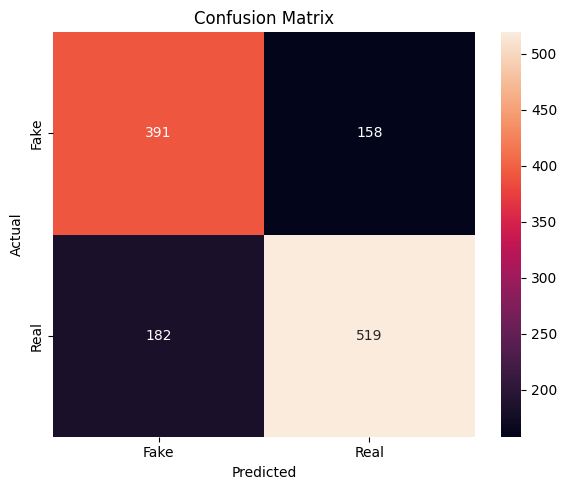

In [ ]:
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,5))

sns.heatmap(cm,annot=True,fmt="d",xticklabels=["Fake","Real"],yticklabels=["Fake","Real"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

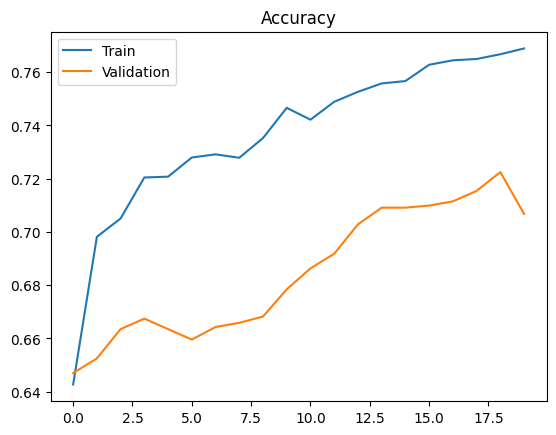

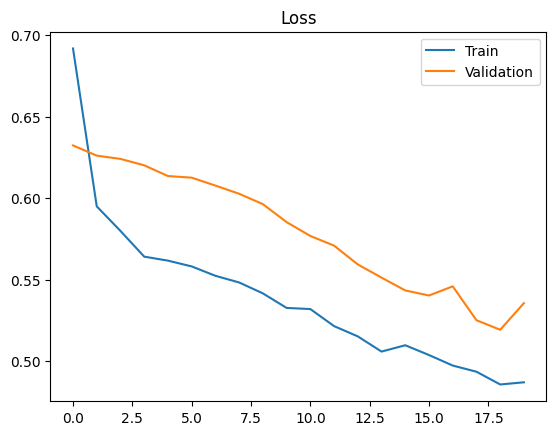

In [ ]:
plt.plot(fusion_history.history["accuracy"])
plt.plot(fusion_history.history["val_accuracy"])

plt.legend(["Train","Validation"])

plt.title("Accuracy")

plt.show()

plt.plot(fusion_history.history["loss"])
plt.plot(fusion_history.history["val_loss"])

plt.legend(["Train","Validation"])

plt.title("Loss")

plt.show()

In [ ]:
nrc = pd.read_csv("NRC-Emotion-Lexicon-Wordlevel-v0.92.txt",sep="\t",header=None,names=["word", "emotion", "association"])
nrc = nrc[nrc["association"] == 1]

emotion_dict = {}
emotion_labels = ['anger','anticipation','disgust','fear','joy','sadness','surprise','trust','positive','negative']

for _, row in nrc.iterrows():
    word = row["word"]
    emotion = row["emotion"]

    if word not in emotion_dict:
        emotion_dict[word] = []

    emotion_dict[word].append(emotion)

def extract_emotions(text):
    counts = Counter()
    words = str(text).split()

    for word in words:
        if word in emotion_dict:
            for emotion in emotion_dict[word]:
                if emotion in emotion_labels:
                    counts[emotion] += 1

    return [counts[e] for e in emotion_labels]

emotion_features_train = np.array(train_df["Combined_Text"].apply(extract_emotions).tolist())
emotion_features_valid = np.array(valid_df["Combined_Text"].apply(extract_emotions).tolist())
emotion_features_test = np.array(test_df["Combined_Text"].apply(extract_emotions).tolist())

emo_scaler = StandardScaler()
emotion_features_train = emo_scaler.fit_transform(emotion_features_train)
emotion_features_valid = emo_scaler.transform(emotion_features_valid)
emotion_features_test = emo_scaler.transform(emotion_features_test)

EMOTION_DIM = emotion_features_train.shape[1]
print("Emotion features shape: ",emotion_features_train.shape)

Emotion features shape:  (10138, 10)


In [ ]:
train_probs = model.predict({"input_ids": X_train_ids,"attention_mask": X_train_mask}).logits
train_probs = tf.nn.softmax(train_probs).numpy()

valid_probs = model.predict({"input_ids": X_valid_ids,"attention_mask": X_valid_mask}).logits
valid_probs = tf.nn.softmax(valid_probs).numpy()

test_probs = model.predict({"input_ids": X_test_ids,"attention_mask": X_test_mask}).logits
test_probs = tf.nn.softmax(test_probs).numpy()

X_train_final = np.concatenate([train_probs,X_train_credit,emotion_features_train],axis=1)
X_valid_final = np.concatenate([valid_probs,X_valid_credit,emotion_features_valid],axis=1)
X_test_final = np.concatenate([test_probs,X_test_credit,emotion_features_test],axis=1)

print(X_train_final.shape)
print(X_valid_final.shape)
print(X_test_final.shape)

40/40 [==============================] - 13s 316ms/step
(10138, 17)
(1272, 17)
(1250, 17)


In [ ]:
fusion_model_emotion = tf.keras.Sequential([
    Dense(64, activation="relu", input_shape=(X_train_final.shape[1],)),
    BatchNormalization(),
    Dropout(0.4),
    Dense(32, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dense(2, activation="softmax")
])

fusion_model_emotion.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=5e-4,weight_decay=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

fusion_model_emotion.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,178 (16.32 KB)

 Trainable params: 3,986 (15.57 KB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
fusion_earlystop_emotion = EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)
fusion_checkpoint_emotion = ModelCheckpoint("best_bert_emotion.keras",monitor="val_accuracy",save_best_only=True,verbose=1)

fusion_history_emotion = fusion_model_emotion.fit(X_train_final,y_train,
    validation_data=(X_valid_final,y_valid),
    epochs=20,
    batch_size=32,
    callbacks=[fusion_earlystop_emotion,fusion_checkpoint_emotion],
    class_weight=class_weights)

fusion_model_emotion.save("bert_emotion.keras")

Epoch 1/20
317/317 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5209 - loss: 0.8028
Epoch 1: val_accuracy improved from -inf to 0.59513, saving model to best_bert_emotion.keras
317/317 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.5469 - loss: 0.7511 - val_accuracy: 0.5951 - val_loss: 0.6624
Epoch 2/20
312/317 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5957 - loss: 0.6815
Epoch 2: val_accuracy improved from 0.59513 to 0.63365, saving model to best_bert_emotion.keras
317/317 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6034 - loss: 0.6726 - val_accuracy: 0.6336 - val_loss: 0.6433
Epoch 3/20
299/317 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6222 - loss: 0.6565
Epoch 3: val_accuracy did not improve from 0.63365
317/317 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6335 - loss: 0.6463 - val_accuracy: 0.6289 - val_loss: 0.6319
Epoch 4/20
311/317 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6620 - loss: 0.6170
Epoch 4: val_accuracy did not improve from 0.63365
317/317 ━━━━

In [ ]:
test_loss, test_acc = fusion_model_emotion.evaluate(X_test_final,y_test)
print("Test Accuracy:", test_acc)

y_pred = fusion_model_emotion.predict(X_test_final)
y_pred = np.argmax(y_pred, axis=1)
print(classification_report(y_test,y_pred,target_names=["Fake", "Real"]))

40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6648 - loss: 0.6327
Test Accuracy: 0.6647999882698059
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
              precision    recall  f1-score   support

        Fake       0.61      0.64      0.63       549
        Real       0.71      0.68      0.70       701

    accuracy                           0.66      1250
   macro avg       0.66      0.66      0.66      1250
weighted avg       0.67      0.66      0.67      1250



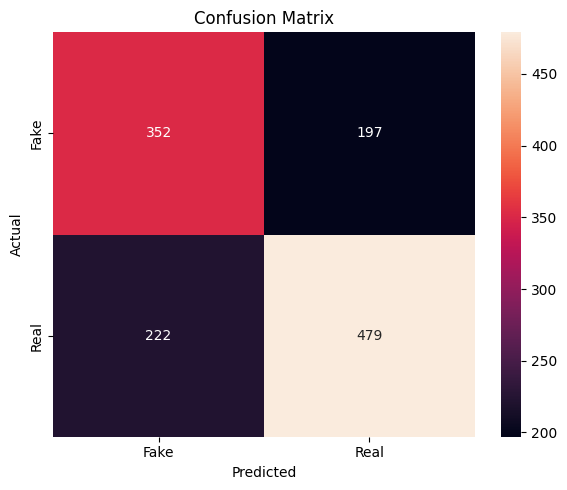

In [ ]:
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,5))

sns.heatmap(cm,annot=True,fmt="d",xticklabels=["Fake","Real"],yticklabels=["Fake","Real"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

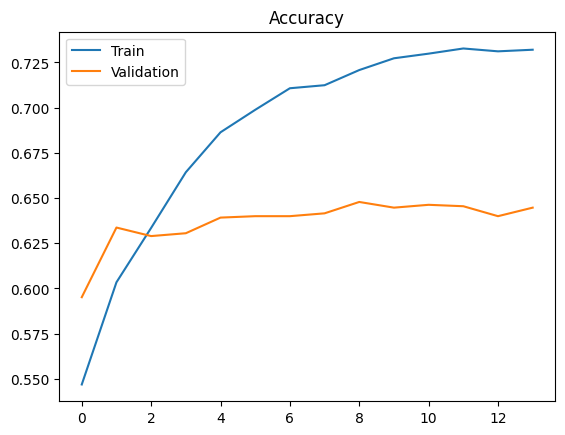

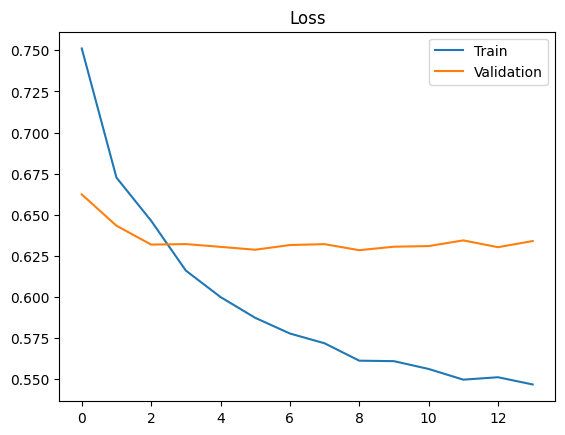

In [ ]:
plt.plot(fusion_history.history["accuracy"])
plt.plot(fusion_history.history["val_accuracy"])

plt.legend(["Train","Validation"])

plt.title("Accuracy")

plt.show()

plt.plot(fusion_history.history["loss"])
plt.plot(fusion_history.history["val_loss"])

plt.legend(["Train","Validation"])

plt.title("Loss")

plt.show()